In [ ]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
import random
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from skimage.feature import hog
from skimage.transform import rotate
from skimage.util import random_noise
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.decomposition import PCA



This cell defines the paths to the training and test datasets and the categories (`dogs` and `cats`).

The `train_dir` variable point to the respective directories containing the images.

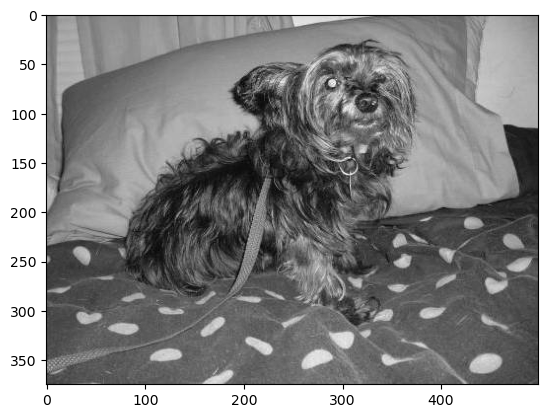

In [ ]:
# Define paths for training and  datasets
train_dir = r'C:\Users\alghad\Downloads\archive\dogs_vs_cats\train'
#test_dir = r'C:\Users\alghad\Downloads\archive\dogs_vs_cats\test'  # Path to the test dataset
categories = ['dogs', 'cats'] 
            
data= []
for category in categories:
    path=os.path.join(train_dir,category)
    label=categories.index(category) #0 for dogs and 1 for cats
    for img in os.listdir(path):
        img_array = cv2.imread(os.path.join(path, img), cv2.IMREAD_GRAYSCALE) #read the image
        plt.imshow(img_array, cmap='gray') #show the image
        plt.show()
        break
    break #stop after one image per category to show the image
cv2.waitKey(0) #wait for a key press to close the image
cv2.destroyAllWindows() #close the image window

This function performs data augmentation by applying random transformations to the input image.

Augmentation increases dataset diversity, which helps the model generalize better.

HOG features capture the structure and texture of an image, which are useful for distinguishing between categories.

In [5]:
# Limit the number of images per category to avoid long processing times
max_images_per_category = 1000

# Function to augment images
def augment_image(img):
    """Apply random rotation, noise, flip, brightness adjustment, and cropping for data augmentation."""
    angle = random.uniform(-15, 15)
    rotated = rotate(img, angle, preserve_range=True)
    noisy = random_noise(rotated, mode='gaussian', var=0.01)
    noisy = (noisy * 255).astype(np.uint8)
    
    # Random horizontal flip
    if random.random() > 0.5:
        noisy = cv2.flip(noisy, 1)
    
    # Random brightness adjustment
    brightness_factor = random.uniform(0.8, 1.2)
    noisy = np.clip(noisy * brightness_factor, 0, 255).astype(np.uint8)
    
    # Random cropping
    h, w = noisy.shape[:2]
    crop_size = random.uniform(0.8, 1.0)
    crop_h, crop_w = int(h * crop_size), int(w * crop_size)
    start_h, start_w = random.randint(0, h - crop_h), random.randint(0, w - crop_w)
    cropped = noisy[start_h:start_h + crop_h, start_w:start_w + crop_w]
    resized = cv2.resize(cropped, (100, 100))
    
    return resized

# Function to extract HOG features
def extract_hog_features(img_path):
    img = cv2.imread(img_path)
    img = cv2.resize(img, (100, 100))
    features = []
    for channel in range(3):  # Extract HOG features for each RGB channel
        channel_features, _ = hog(img[:, :, channel], orientations=9, pixels_per_cell=(8, 8),
                                  cells_per_block=(2, 2), visualize=True)
        features.extend(channel_features)
    return features

This cell loads the images, extracts HOG features, and stores them along with their labels.

It also limits the number of images per category to 1000 and shuffles the data for randomness.

In [39]:
#prepere the data
data = []
original_images = []  # Store original image paths for visualization

for category in categories:
    path = os.path.join(train_dir, category)
    label = categories.index(category)
    count = 0
    for img in os.listdir(path):
        if count >= max_images_per_category:
            break
        img_path = os.path.join(path, img)
        feat = extract_hog_features(img_path)
        data.append([feat, label])
        original_images.append(img_path)
     
        # Add augmented versions
        img_array = cv2.imread(img_path)
        resized_img = cv2.resize(img_array, (100, 100))
        for _ in range(2):  # Add two augmented versions
            augmented_img = augment_image(resized_img)
            aug_features = extract_hog_features(img_path)
            data.append([aug_features, label])
            original_images.append(img_path)
        count += 1


# Shuffle the training data
random.shuffle(data)

# Split features and labels
# Split features and labels for training data
features = []
labels = []
for feature, label in data:
    features.append(feature)
    labels.append(label)

X = np.array(features)
y = np.array(labels)

PCA is applied to reduce the dimensionality of the HOG features to 200 components.

The dataset is then split into training (80%) and testing (20%) sets.

In [40]:
# Split the dataset into training and testing sets

# Apply PCA
pca = PCA(n_components=200)  # You can tune n_components
X_pca = pca.fit_transform(X)

# Split the dataset into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(X_pca, y, test_size=0.2, random_state=42)

# Print dataset sizes
print(f"Training samples: {len(x_train)}")
print(f"Testing samples: {len(x_test)}")

 

Training samples: 4800
Testing samples: 1200


In [41]:
from sklearn.model_selection import RandomizedSearchCV

# Reduce the dataset size for hyperparameter tuning
x_train_sample, _, y_train_sample, _ = train_test_split(x_train, y_train, test_size=0.8, random_state=42)

# SVM Hyperparameter Tuning with RandomizedSearchCV
svm_params = {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf'], 'gamma': ['scale', 'auto']}
svm_random = RandomizedSearchCV(SVC(), svm_params, n_iter=5, cv=3, scoring='accuracy', random_state=42)
svm_random.fit(x_train_sample, y_train_sample)
print("Best SVM Parameters:", svm_random.best_params_)

# Random Forest Hyperparameter Tuning with RandomizedSearchCV
rf_params = {'n_estimators': [50, 100, 200], 'max_depth': [None, 10, 20]}
rf_random = RandomizedSearchCV(RandomForestClassifier(random_state=42), rf_params, n_iter=5, cv=3, scoring='accuracy', random_state=42)
rf_random.fit(x_train_sample, y_train_sample)
print("Best Random Forest Parameters:", rf_random.best_params_)

# Print dataset split sizes
print(f"Total samples: {len(X_pca)}")  # Fixed: Replaced X with X_train
print(f"Training samples: {len(x_train)}")
print(f"Testing samples: {len(x_test)}")

Best SVM Parameters: {'kernel': 'rbf', 'gamma': 'scale', 'C': 1}
Best Random Forest Parameters: {'n_estimators': 200, 'max_depth': 20}
Total samples: 2457
Training samples: 4800
Testing samples: 1200


In [42]:
# --- SVM Model ---
#model = SVC({'C':1,'kerenal':'rbf','gamma':'scale'})
model = SVC(C=0.5, kernel='rbf', gamma='scale')
model.fit(x_train, y_train)
y_pred = model.predict(x_test)
print('PCA(HOG)+SVM Accuracy:', accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=categories))

# --- Random Forest Model ---
rf_model = RandomForestClassifier(n_estimators=5, random_state=42, max_depth=20)
rf_model.fit(x_train, y_train)
rf_pred = rf_model.predict(x_test)
print("\nRandom Forest Results (PCA on HOG):")
print("Accuracy:", accuracy_score(y_test, rf_pred))
print(classification_report(y_test, rf_pred, target_names=categories))


PCA(HOG)+SVM Accuracy: 0.9125
              precision    recall  f1-score   support

        dogs       0.92      0.91      0.91       604
        cats       0.91      0.92      0.91       596

    accuracy                           0.91      1200
   macro avg       0.91      0.91      0.91      1200
weighted avg       0.91      0.91      0.91      1200


Random Forest Results (PCA on HOG):
Accuracy: 0.9716666666666667
              precision    recall  f1-score   support

        dogs       0.97      0.98      0.97       604
        cats       0.98      0.97      0.97       596

    accuracy                           0.97      1200
   macro avg       0.97      0.97      0.97      1200
weighted avg       0.97      0.97      0.97      1200



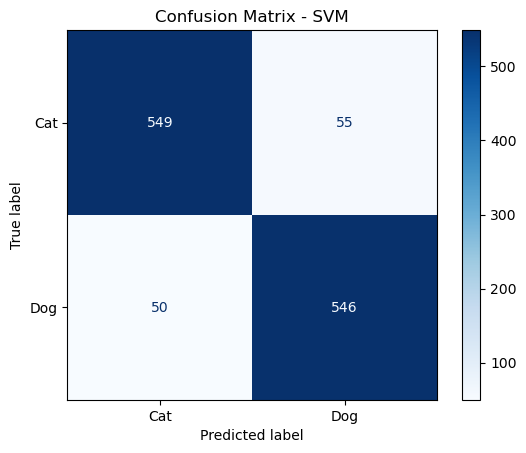

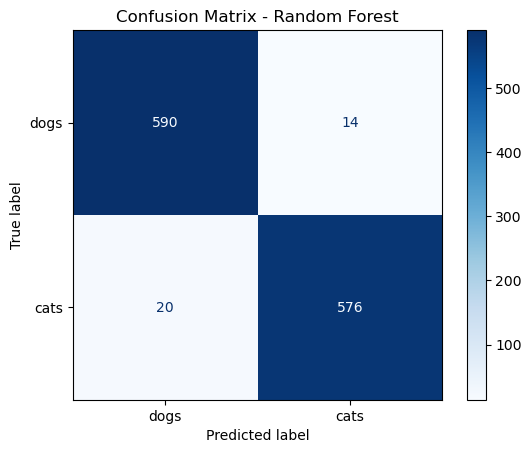


The Random Forest model is better based on accuracy.


In [43]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Confusion Matrix for SVM
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Cat", "Dog"])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix - SVM")
plt.show()

# Confusion Matrix for Random Forest
cm_rf = confusion_matrix(y_test, rf_pred)
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=categories)
disp_rf.plot(cmap='Blues')
plt.title("Confusion Matrix - Random Forest")
plt.show()

# --- Determine the Best Model ---
svm_accuracy = accuracy_score(y_test, y_pred)
rf_accuracy = accuracy_score(y_test, rf_pred)

if svm_accuracy > rf_accuracy:
    print("\nThe SVM model is better based on accuracy.")
elif rf_accuracy > svm_accuracy:
    print("\nThe Random Forest model is better based on accuracy.")
else:
    print("\nBoth models have the same accuracy.")

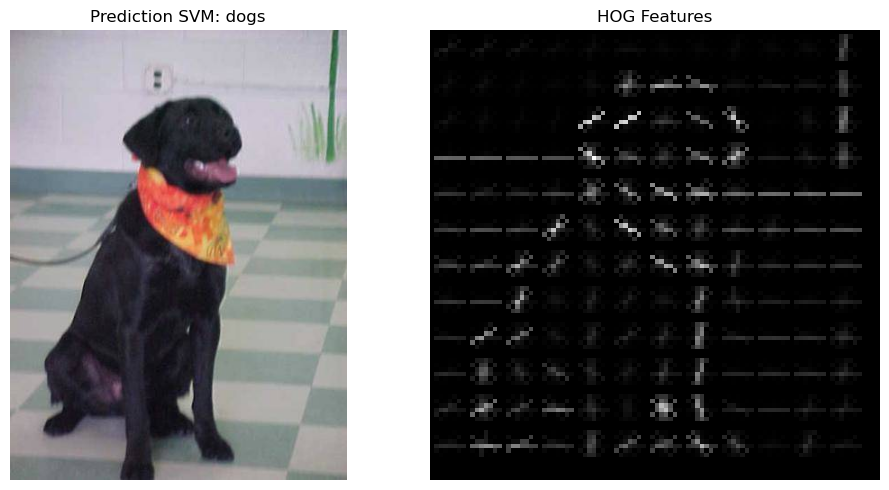

In [45]:
#Visualization for a random test image (using SVM)
random_index = random.randint(0, len(x_test) - 1)
output_features = x_test[random_index]
predicted_label = model.predict([output_features])[0]
original_image_path = original_images[random_index]
original_image = cv2.imread(original_image_path)
original_image = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title(f"Prediction SVM: {categories[predicted_label]}")
plt.axis('off')

plt.subplot(1, 2, 2)
hog_features, hog_image = hog(cv2.cvtColor(cv2.resize(original_image, (100, 100)), cv2.COLOR_RGB2GRAY),
                             orientations=9,
                             pixels_per_cell=(8, 8),
                             cells_per_block=(2, 2),
                             visualize=True)
plt.imshow(hog_image, cmap='gray')
plt.title('HOG Features')
plt.axis('off')

plt.tight_layout()
plt.show()


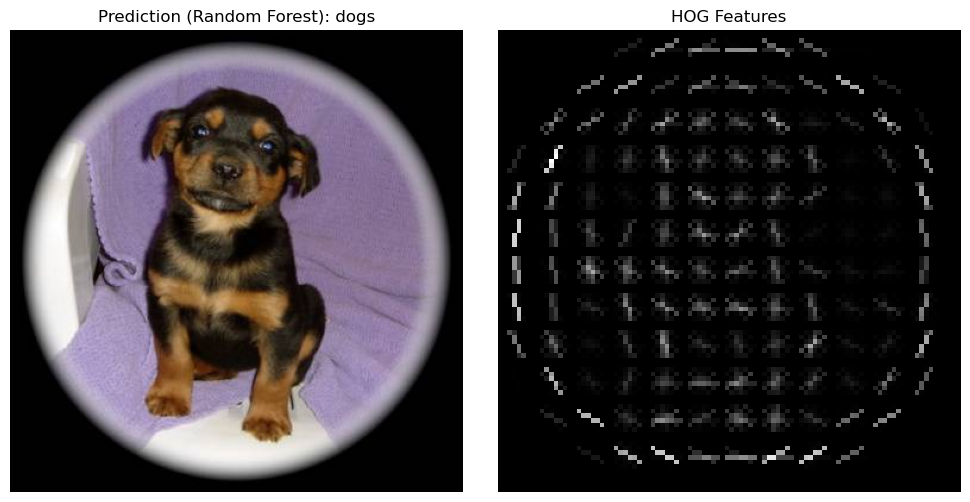

: 

In [ ]:
# Visualization for a random test image (using Random Forest)
random_index = random.randint(0, len(x_test) - 1)
output_features = x_test[random_index]
predicted_label_rf = rf_model.predict([output_features])[0]
original_image_path = original_images[random_index]
original_image = cv2.imread(original_image_path)
original_image = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title(f"Prediction (Random Forest): {categories[predicted_label_rf]}")
plt.axis('off')

plt.subplot(1, 2, 2)
hog_features, hog_image = hog(cv2.cvtColor(cv2.resize(original_image, (100, 100)), cv2.COLOR_RGB2GRAY),
                             orientations=9,
                             pixels_per_cell=(8, 8),
                             cells_per_block=(2, 2),
                             visualize=True)
plt.imshow(hog_image, cmap='gray')
plt.title('HOG Features')
plt.axis('off')

plt.tight_layout()
plt.show()